In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2

#### Premières infos

In [ ]:
df = pd.read_csv("agences_acp.csv",
                 sep=";", decimal=",")
# pas besoin de copy() car set_index() renvoi un nouveau dataframe
df_base = df.set_index("Agence") 
 
df_base.info()    
display(df_base)

<class 'pandas.DataFrame'>
Index: 138 entries, AG001 to AG138
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CA_MFCFA       138 non-null    float64
 1   Nb_clients     138 non-null    int64  
 2   Encours_MFCFA  138 non-null    float64
 3   Taux_impayes   138 non-null    float64
 4   Delai_jours    138 non-null    float64
 5   Satisfaction   138 non-null    float64
 6   Effectif       138 non-null    int64  
dtypes: float64(5), int64(2)
memory usage: 8.6+ KB


,CA_MFCFA,Nb_clients,Encours_MFCFA,Taux_impayes,Delai_jours,Satisfaction,Effectif
Agence,,,,,,,
AG001,176.9,2788,383.9,8.12,14.5,5.32,6
AG002,172.5,1399,313.2,9.58,13.3,6.57,2
AG003,280.1,1245,693.3,7.35,14.1,5.92,4
AG004,590.8,3731,1403.1,3.27,9.3,7.35,13
AG005,570.4,4745,1387.6,3.77,6.4,8.41,17
...,...,...,...,...,...,...,...
AG134,422.8,3686,983.0,6.18,7.0,7.83,5
AG135,648.5,3892,1454.1,3.62,7.3,7.64,17
AG136,300.2,2789,703.6,7.48,3.7,8.46,6


In [4]:
print(df_base.shape)
print(df_base.isna().sum().sum())
print(df_base.duplicated().sum())
print(df_base.index.duplicated().sum())

(138, 7)
0
0
0


#### Valeurs aberrantes puisque les max font de 5 à 8 fois le Q3 alors que la dispersion paraît normale.

In [5]:
df_base.describe().round(2) 

,CA_MFCFA,Nb_clients,Encours_MFCFA,Taux_impayes,Delai_jours,Satisfaction,Effectif
count,138.00,138.00,138.00,138.00,138.00,138.00,138.00
mean,425.63,3107.36,961.45,6.99,9.49,7.02,8.93
std,285.20,2074.29,645.13,5.24,7.70,1.09,5.16
min,126.10,708.00,276.60,2.10,3.40,4.42,2.00
25%,259.33,2007.50,613.78,5.05,6.40,6.21,6.00
50%,353.05,2544.00,830.25,7.06,8.35,7.32,8.00
75%,588.40,4201.25,1270.12,8.02,11.60,7.83,12.00
max,2950.00,21400.00,6840.00,64.00,92.00,8.87,46.00


#### Univarié

Deux agences dépassent le seuil de 3 (convention par rapport à la loi normale) avec des anomalies différentes.

In [6]:
df_base_cr = (df_base - df_base.mean()) / df_base.std() # centrer et réduire

# masque de seuil supp. à 3 
seuil = (df_base_cr.abs() > 3).any(axis=1)

df_base_cr_seuil = df_base_cr[seuil]

display(df_base_cr_seuil)

,CA_MFCFA,Nb_clients,Encours_MFCFA,Taux_impayes,Delai_jours,Satisfaction,Effectif
Agence,,,,,,,
AG017,8.851214,8.818751,9.112191,-0.931792,-0.388859,0.303735,7.188954
AG093,-0.329684,-0.239771,-0.280634,10.873251,10.715075,0.944365,-0.179864


#### Multivarié, Mahalanobis

In [7]:
variables_actives = ["CA_MFCFA", "Nb_clients",
           "Encours_MFCFA", "Taux_impayes",
           "Delai_jours", "Satisfaction"]
variable_sup = "Effectif"

Inverse de la matrice de covariance = matrice de précision.  
Tient compte à la fois de l'échelle des variables et de leurs corrélations.  
⇒ permet de savoir à quel point une observation s'écarte du groupe de données SANS traiter comme indépendantes des variables qui sont corrélées.  

*la matrice doit être inversible, pas possible si variables redondantes ou si trop peu d'observations*

##### Calcul de la distance de Mahalanobis au carré de chaque observation et le seuil qui permet de détecter les valeurs éloignées

In [8]:
X_all = df_base_cr[variables_actives].values
# display(all_X[:3, :])

centre = X_all.mean(axis=0) # de chaque colonne

S_inv = np.linalg.inv(np.cov(X_all, rowvar=False)) # rowvar=False indique que les lignes sont les observations et les colonnes les variables

ecart = X_all - centre # chaque ligne devient une observation centrée

d2 = np.sum((ecart @ S_inv) * ecart, axis=1) # @ produit matriciel VS élément par élément comme *

seuil_maha = chi2.ppf(0.999, df=len(variables_actives))
# 0.999 = 99,9 centile ou percentile // distribution données divisée en 100 parts égales 
masque_maha = d2 > seuil_maha

df_maha = df_base_cr[masque_maha]
display(df_maha)

print(f"agence AG017 : {d2[16]}")
print(f"agence AG093 : {d2[92]}")

,CA_MFCFA,Nb_clients,Encours_MFCFA,Taux_impayes,Delai_jours,Satisfaction,Effectif
Agence,,,,,,,
AG017,8.851214,8.818751,9.112191,-0.931792,-0.388859,0.303735,7.188954
AG093,-0.329684,-0.239771,-0.280634,10.873251,10.715075,0.944365,-0.179864


agence AG017 : 107.87220394194216
agence AG093 : 133.11619123302364


 Le diagnostique multivarié confirme l'univarié : le problème est circonscrit à deux agences.  

Les deux aberrants pèsent tellement lourd à eux seuls qu'ils faussent l'analyse.  
En analyse factorielle, on choisit la mise en supplémentaire qui est la solution de référence : l'individu reste visible sur les graphiques sans déformer les axes.

#### Traitement aberrants 

In [9]:
print(df_base.loc["AG017"])
print(df_base.loc["AG093"])

#  traitement ⇒ ces agences sont "mises en supplémentaire"

CA_MFCFA          2950.00
Nb_clients       21400.00
Encours_MFCFA     6840.00
Taux_impayes         2.10
Delai_jours          6.50
Satisfaction         7.35
Effectif            46.00
Name: AG017, dtype: float64
CA_MFCFA          331.60
Nb_clients       2610.00
Encours_MFCFA     780.40
Taux_impayes       64.00
Delai_jours        92.00
Satisfaction        8.05
Effectif            8.00
Name: AG093, dtype: float64


In [10]:
aberrants = ["AG017", "AG093"]
# les 136 agences actives
df_act = df_base.drop(index=aberrants)   
# les 2 agences supplémentaires 
df_sup = df_base.loc[aberrants]

#### Corrélations variables

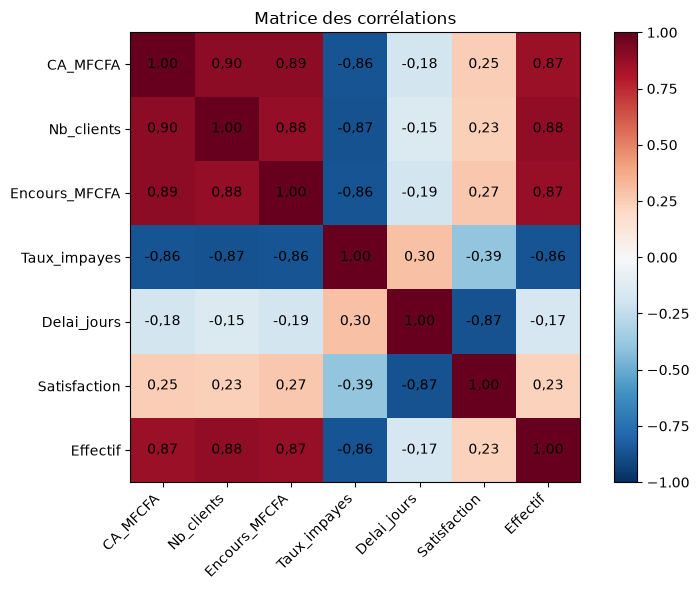

In [11]:
correlations = df_act.corr()

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(correlations.columns)))
ax.set_xticklabels(correlations.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlations.index)))
ax.set_yticklabels(correlations.index)

# Affiche la valeur de chaque corrélation dans sa case
for i, j in np.ndindex(correlations.shape):
    ax.text(j, i, f"{correlations.iloc[i, j]:.2f}".replace(".", ","),
            ha="center", va="center")

fig.colorbar(image, ax=ax)
ax.set_title("Matrice des corrélations")
plt.tight_layout()
plt.show()

Deux blocs peu liés entre eux : on peut s'attendre à deux dimensions bien distinctes.  

Seules les variables actives construisent les axes. Les supplémentaires sont projetées après coup : elles aident à interpréter sans influencer.  

L'effectif mesure un moyen, pas une performance. Et il est quasi redondant avec le bloc volume (r ≈ 0,87) : actif, il sur-pondérerait ce bloc.  
En supplémentaire, il répond à une question nouvelle sans biaiser les axes : les performances sont-elles liées aux moyens humains ?

6 variables actives (les performances) et 1 variable quantitative supplémentaire (l'effectif). Le même raisonnement vaut pour les individus : 136 actifs, 2 supplémentaires.

#### Centrer et réduire

In [12]:
data_x = df_act[variables_actives].values
n, p = data_x.shape
print(n, p)

moyennes = data_x.mean(axis=0)
ecarts = data_x.std(axis=0)

data_cr = (data_x - moyennes) / ecarts

136 6


Attention : la corrélation usuelle calculée par pandas.corr() utilise une normalisation par n - 1.  
Il faut donc vérifier comment data_cr a été standardisé et calculer n comme le nombre de lignes.

#### Diagonaliser R (matrice de corrélations)

valeurs propres : quantité de variance portée par chaque axe
colonne de vecteurs : vecteurs propres correspondant donnent les directions de ces axes.

Les axes sont donc les vecteurs propres de la matrice de corrélations, la valeur propre d'un axe = l'inertie qu'il restitue.

In [13]:
mat_corr = data_cr.T @ data_cr / n      
# .T transpose les variables en lignes       
# matrice carrée des corrélations sur des variables centrées / réduites 

valp, vecp = np.linalg.eigh(mat_corr) # ordre croissant
# calcule les valeurs propres et les vecteurs propres d'une matrice symétrique

ordre = np.argsort(valp)[::-1] # tri décroissant
valp = valp[ordre]
vecp = vecp[:, ordre]

# ⇒ Les colonnes de vecp correspondent alors aux axes principaux, du plus important au moins important

ICI calcul de la corrélation "à la main" sur des datas centrées et réduites, et normalisée.  

VS la formule numpy 
```py 
np.corrcoef(X, rowvar = False)
```
qui n'a pas besoin de centre / réduire

ou la fomrule pandas  
```py 
df.corr()
```
où chaque colonne du DataFrame est une variable, les lignes sont les observations.

MAIS pandas ignore les valeurs manquantes paire de colonnes par paire; NumPy peut propager les NaN dans le résultat.

In [14]:
print(valp.sum()) # = 6 car somme des coeeficients sur la diagonale = TRACE
# ⇒ matrice de corrélation, la trace est donc toujours égale au nombre de variables (ici 6)

6.000000000000002


##### Comprendre l'inversement des axes // choix appliqués à la main

In [15]:
idx_ca = variables_actives.index("CA_MFCFA")
idx_sat = variables_actives.index("Satisfaction")

print("Indice de CA_MFCFA :", idx_ca)
print("Coefficient :", vecp[idx_ca, 0])
print("Vecteur Dim1 :", vecp[:, 0])
print("-" * 50)

if vecp[idx_ca, 0] < 0:
    print("Le coefficient est négatif : on inverse Dim1")
    vecp[:, 0] = -vecp[:, 0]
else:
    print("Le coefficient est positif ou nul : on ne change rien")

print("Vecteur Dim1 après :", vecp[:, 0])

Indice de CA_MFCFA : 0
Coefficient : -0.4712215848018953
Vecteur Dim1 : [-0.47122158 -0.46722629 -0.46985533  0.48039282  0.21057525 -0.25252046]
--------------------------------------------------
Le coefficient est négatif : on inverse Dim1
Vecteur Dim1 après : [ 0.47122158  0.46722629  0.46985533 -0.48039282 -0.21057525  0.25252046]


In [16]:
idx_sat = variables_actives.index("Satisfaction")

print("Coefficient de Satisfaction sur Dim2 :", vecp[idx_sat, 1])
print("-" * 50)

if vecp[idx_sat, 1] < 0:
    print("Le coefficient est négatif : on inverse Dim2")
    vecp[:, 1] = -vecp[:, 1]
else:
    print("Le coefficient est positif ou nul : on ne change rien")

print("Vecteur Dim2 après :", vecp[:, 1])

Coefficient de Satisfaction sur Dim2 : 0.6466241049348471
--------------------------------------------------
Le coefficient est positif ou nul : on ne change rien
Vecteur Dim2 après : [-0.19116349 -0.21086211 -0.17919594  0.07055462 -0.68101528  0.6466241 ]


In [17]:
display(pd.DataFrame(
    vecp,
    index=variables_actives,
    columns=["Dim1", "Dim2"] + [f"Dim{i+1}" for i in range(2, vecp.shape[1])]
))

,Dim1,Dim2,Dim3,Dim4,Dim5,Dim6
CA_MFCFA,0.471222,-0.191163,-0.370296,-0.239150,0.079583,-0.735365
Nb_clients,0.467226,-0.210862,0.058995,-0.558374,0.354338,0.544444
Encours_MFCFA,0.469855,-0.179196,-0.326405,0.746591,0.078010,0.277671
Taux_impayes,-0.480393,0.070555,-0.630557,-0.045481,0.599608,0.071025
Delai_jours,-0.210575,-0.681015,0.462831,0.203604,0.438433,-0.209728
Satisfaction,0.252520,0.646624,0.375560,0.173510,0.557021,-0.191539


##### Signe de l'axe

Le signe d'un axe est arbitraire, si u est un vecteur propre alors -u son opposé aussi, mais on fixe le sens pour que la lecture soit naturelle.

```vecp[i, j]``` est le coefficient de la variable i sur la dimension j

In [18]:
# Dim1 orientée par le chiffre d'affaires
if vecp[variables_actives.index("CA_MFCFA"), 0] < 0:
    # si le premier coeff est négatif alors  
    vecp[:, 0] = -vecp[:, 0]
 
# Dim2 orientée par la satisfaction
if vecp[variables_actives.index("Satisfaction"), 1] < 0:
    vecp[:, 1] = -vecp[:, 1]

##### Valeurs propres et inertie

In [19]:
inertie = 100 * valp / p
cumul = 100 * np.cumsum(valp) / p

print(inertie)
print(cumul)

[64.53893628 27.55107212  2.42329077  2.04699223  1.83451565  1.60519294]
[ 64.53893628  92.09000841  94.51329918  96.56029141  98.39480706
 100.        ]


In [20]:
dimensions = [f"Dim{i+1}" for i in range(len(valp))]

display(pd.DataFrame({
    "Valeur propre": valp,
    "Inertie expliquée (%)": inertie,
    "Inertie cumulée (%)": cumul,
}, index=dimensions).round(2))

,Valeur propre,Inertie expliquée (%),Inertie cumulée (%)
Dim1,3.87,64.54,64.54
Dim2,1.65,27.55,92.09
Dim3,0.15,2.42,94.51
Dim4,0.12,2.05,96.56
Dim5,0.11,1.83,98.39
Dim6,0.10,1.61,100.00


Premier plan (dim 1 & 2) restitue (cumul) 92 % de l'inertie VS seulement 82% sans le traitement des aberants.

#### Choisir le nombre d'axes // Critères décision nombre dimensions

Kaiser $λ >$ valeur propre moyenne 

Karlis, Saporta, Spinakis = $λ > 1 + 2\sqrt{((p−1)/(n−1))}$
*Plus exigeant que Kaiser*

Bâton brisé = $λ >$ partage aléatoire de l'inertie 

Éboulis = coude dans la courbe

Interpétabilité = axes que l'on sait nommer

In [22]:
kss = 1 + 2 * np.sqrt((p - 1) / (n - 1))
print(kss) # ici 1,38

baton = np.array([np.sum(1 / np.arange(k, p + 1)) for k in range(1, p + 1)])
print(baton)

1.3849001794597506
[2.45       1.45       0.95       0.61666667 0.36666667 0.16666667]


si on veut faire un cluster d'individus on veut que la vairance soit faile entre eux et faible avec les autres clusters

### SIGNALER SANS MODIFIER

In [ ]:
RAPPORT, ANOMALIES = [], []

def controle(t, regle, severite, echec, col):
    echec = echec.fillna(False)
    RAPPORT.append({"regle": regle,
                    "severite": severite,
                    "nb_echecs": int(echec.sum())})
    for i in t.index[echec]:
        ANOMALIES.append({"ligne": i + 2,
                          "regle": regle,
                          "colonne": col})


In [ ]:
print(len(df), "lignes pour", BORDEREAU["nb_prets"])
 
manquantes = [c for c in ATTENDUES
              if c not in df.columns]
en_trop = [c for c in df.columns
           if c not in ATTENDUES]
vides = [c for c in df.columns
         if est_manquant(df[c]).all()]


In [ ]:
lignes_vides = df.apply(est_manquant).all(axis=1)
controle(df, "Pas de ligne vide", "ALERTE",
         lignes_vides, None)
print(list(df.index[lignes_vides] + 2))
 
t = df[~lignes_vides]    # la suite porte sur t
